プロンプト「
Autoencoderのエンコーダーの第一層のフィルターを画像として表示してください．
matplotlibを用いてください．
」

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt



class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU()
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

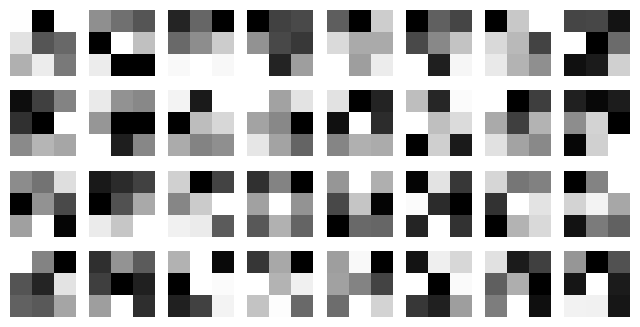

In [2]:
def plot_kernels(tensor, num_cols=8, filename=None):
    num_kernels = tensor.shape[0]
    num_rows = num_kernels // num_cols
    fig = plt.figure(figsize=(num_cols, num_rows))
    for i in range(num_kernels):
        ax = fig.add_subplot(num_rows, num_cols, i + 1)
        # グレースケール画像としてフィルターを表示
        ax.imshow(tensor[i, 0, :, :].detach().cpu(), cmap='gray')
        ax.axis('off')
    plt.savefig(filename)
    plt.show()

# モデルインスタンスを作成
model = Autoencoder()

# エンコーダーの第一層のフィルターを取得
filters = model.encoder[0].weight.data.clone()

# フィルターを表示
import os
os.makedirs("image_executed", exist_ok=True)
filename = "image_executed/encoder0_filter.png"
plot_kernels(filters, filename=filename)


プロンプト「torchsummaryを用いてAutoencoderクラスをまとめてください．」


In [3]:

have_torchsummary = False
try:
    from torchsummary import summary
    have_torchsummary = True
except ModuleNotFoundError:
    have_torchsummary = False
    
if have_torchsummary:
    # モデルの可視化 (例として 1チャネル 64x64 の入力画像を使用)
    summary(model, (1, 64, 64))
